# 프로젝트 데이터 EDA — KOCOH v.2

**주제**: 게시글 맥락 추가에 따른 한국어 혐오표현 탐지 성능 비교 (Comment-only vs Context + Comment)

이 노트북은 세 가지를 한곳에 정리합니다.

1. `data/KOCOH_v.2.csv` 기초 EDA — 크기 · 열별 결측 비율 · 수치형 범위 · 예측 대상(`Hate speech`) 비율 (1~5장)
2. **이전 분할 방식(행 단위)의 문제** — 같은 게시글 맥락이 train/test에 겹치는 것을 예시로 확인 (6장)
3. **변경한 분할 방식(게시글 묶음 단위)** 과 `src/preprocess.py` 의 `load_and_split()` — 이전 방식과 나란히 비교 (7~8장)

그림은 `src/preprocess.py` 가 이미 `figures/` 에 저장한 파일을 불러와 보여주기만 합니다
(노트북을 실행해도 기존 그림을 덮어쓰지 않음). 다시 만들려면 터미널에서
`python src/preprocess.py --eda` (EDA 그림 2장) / `python src/preprocess.py` (분할 비교 그림) 를 실행합니다.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path('..').resolve()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = Path('.').resolve()  # repo 루트에서 실행하는 경우
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

import preprocess as pp

SEED = pp.SEED
np.random.seed(SEED)
print(f"seed = {SEED}")
print(f"데이터 경로: {pp.DATA_PATH.relative_to(PROJECT_ROOT)}")

seed = 42
데이터 경로: data/KOCOH_v.2.csv


## 1. 데이터 읽기와 크기

In [2]:
df = pd.read_csv(pp.DATA_PATH)
pd.DataFrame({"행": [df.shape[0]], "열": [df.shape[1]]})

,행,열
0,3000,18


In [3]:
df.head(3)

,Index,Set,Type,Date,Source,Link,Title,Context,Comment,Hate speech,Counter speech,Gender,Disability,Race/Nationality,Region (Korea),Age,Profanity,Ikiyano-style
0,1,1,1,2024-06-02,디시인사이드,https://gall.dcinside.com/board/view/?id=dcbes...,싱글벙글 이제부터 여성 안 뽑는 '여혐업체' 박제한다....jpg,여성 고용이 미흡해 정부가 불이익을 준 기업의 이름이 공개되었다.,미래가 밝은 회사이니 투자하라는 뜻에서 샤라웃 해주는 거임,1,0,1,0,0,0,0,0,0
1,2,1,1,2024-06-02,디시인사이드,https://gall.dcinside.com/board/view/?id=dcbes...,싱글벙글 이제부터 여성 안 뽑는 '여혐업체' 박제한다....jpg,여성 고용이 미흡해 정부가 불이익을 준 기업의 이름이 공개되었다.,쉐보레 차 좋은데엔 이유가 있었노,1,0,1,0,0,0,0,0,1
2,3,1,1,2024-06-02,디시인사이드,https://gall.dcinside.com/board/view/?id=dcbes...,싱글벙글 이제부터 여성 안 뽑는 '여혐업체' 박제한다....jpg,여성 고용이 미흡해 정부가 불이익을 준 기업의 이름이 공개되었다.,풀매수 간다,1,0,1,0,0,0,0,0,0


## 2. 열별 결측 비율

결측 행은 **지우지 않고** 개수와 비율만 셉니다.

In [4]:
missing = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "결측 개수": df.isna().sum(),
    "결측 비율(%)": (df.isna().mean() * 100).round(3),
})
missing

,dtype,결측 개수,결측 비율(%)
Index,int64,0,0.000
Set,int64,0,0.000
Type,int64,0,0.000
Date,str,764,25.467
Source,str,764,25.467
Link,str,764,25.467
Title,str,764,25.467
Context,str,0,0.000
Comment,str,0,0.000
Hate speech,int64,0,0.000


In [5]:
# 결측이 있는 열들이 같은 행에서 동시에 비는지 확인
miss_cols = missing.index[missing["결측 개수"] > 0].tolist()
all_missing = df[miss_cols].isna().all(axis=1)
any_missing = df[miss_cols].isna().any(axis=1)
print("결측 있는 열:", miss_cols)
print("한 열이라도 결측인 행:", int(any_missing.sum()), "/ 모든 열이 동시에 결측인 행:", int(all_missing.sum()))

결측 있는 열: ['Date', 'Source', 'Link', 'Title']
한 열이라도 결측인 행: 764 / 모든 열이 동시에 결측인 행: 764


## 3. 수치형 열 범위

In [6]:
num = df.select_dtypes(include="number")
pd.DataFrame({
    "min": num.min(),
    "max": num.max(),
    "mean": num.mean().round(3),
    "고유값 수": num.nunique(),
})

,min,max,mean,고유값 수
Index,1,3000,1500.500,3000
Set,1,101,47.227,101
Type,1,3,2.236,3
Hate speech,0,1,0.255,2
Counter speech,0,1,0.019,2
Gender,0,1,0.123,2
Disability,0,1,0.008,2
Race/Nationality,0,1,0.066,2
Region (Korea),0,1,0.072,2
Age,0,1,0.026,2


## 4. 예측 대상 `Hate speech` 비율

In [7]:
counts = df[pp.TARGET].value_counts(dropna=False).sort_index()
target_tbl = pd.DataFrame({"개수": counts, "비율(%)": (counts / counts.sum() * 100).round(3)})
target_tbl.index.name = f"{pp.TARGET} (0=비혐오, 1=혐오)"
target_tbl

,개수,비율(%)
"Hate speech (0=비혐오, 1=혐오)",,
0,2236,74.533
1,764,25.467


### EDA 그림 (`figures/` 에 저장된 파일)

figures/kocoh_missing_ratio.png


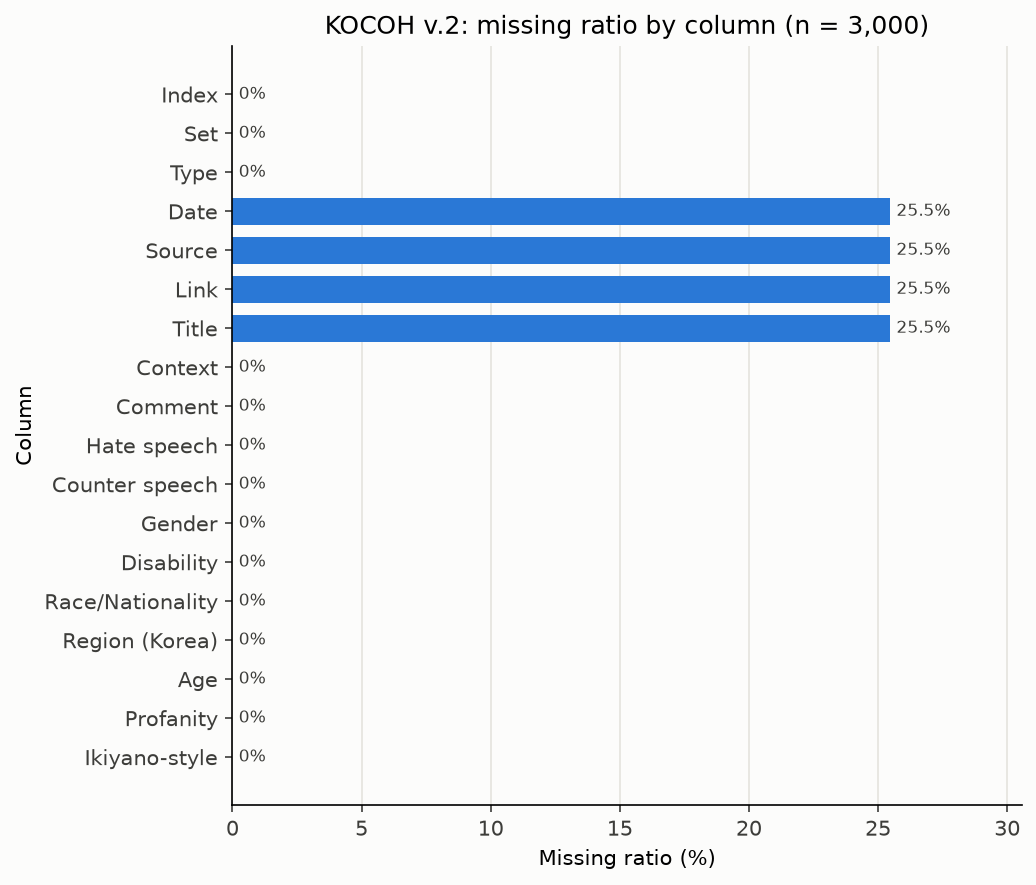

figures/kocoh_class_ratio.png


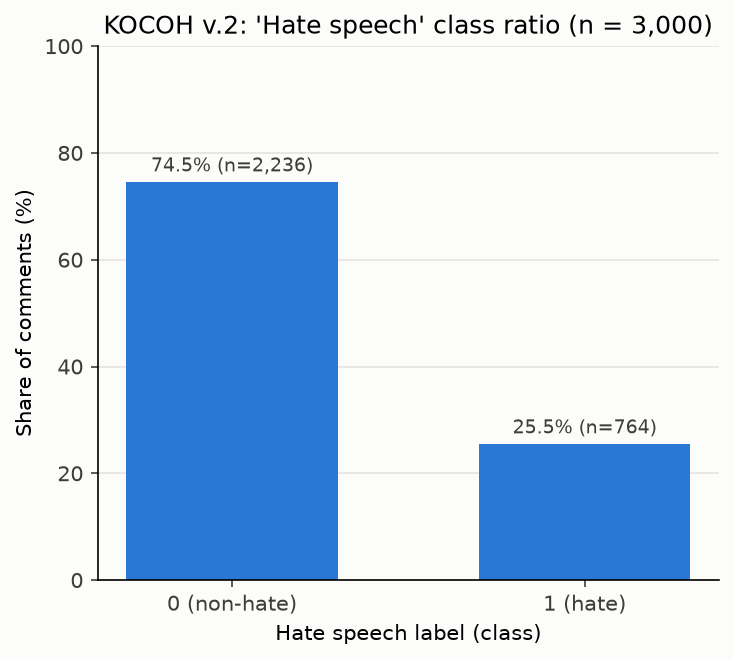

In [8]:
for name in ["kocoh_missing_ratio.png", "kocoh_class_ratio.png"]:
    path = PROJECT_ROOT / "figures" / name
    print(path.relative_to(PROJECT_ROOT))
    display(Image(filename=str(path), width=520))

## 5. 라벨 누설 점검: `Type` 과 메타 열 결측

`Type` 과 결측 여부가 정답 라벨과 어떻게 연결되는지 교차표로 확인합니다.

In [9]:
pd.crosstab(df["Type"], df[pp.TARGET], margins=True)

Hate speech,0,1,All
Type,,,
1,0,764,764
2,764,0,764
3,1472,0,1472
All,2236,764,3000


In [10]:
pd.crosstab(df["Type"], any_missing.rename("메타 4열 결측"), margins=True)

메타 4열 결측,False,True,All
Type,,,
1,764,0,764
2,0,764,764
3,1472,0,1472
All,2236,764,3000


## 6. 이전 분할 방식(행 단위)의 문제: 겹치는 게시글 맥락

### 6-1. 무엇이 문제인가 — 시험 문제에 비유하면

각 데이터 한 줄은 **지문(`Context`, 게시글 요약)** 과 **문제(`Comment`, 댓글)** 의 쌍이고, 지문 하나에 문제(댓글)가 여러 개 딸려 있습니다.

이전 방식은 3,000개 문제를 **한 줄씩 섞어서** 80%는 공부용(train), 20%는 시험용(test)으로 나눴습니다.
그러면 **시험지에 나온 지문 대부분을 공부할 때 이미 본** 상태가 됩니다.

- Context + Comment 모델은 "이 지문에 달린 댓글은 혐오가 많았다" 같은 **지문별 경향을 외워서** 점수를 얻을 수 있습니다.
- Comment-only 모델은 지문을 보지 않으므로 이 이득이 없습니다.
- 결과적으로 **"맥락을 넣으면 성능이 오르는가"** 라는 프로젝트의 핵심 비교가 맥락 쪽에 유리하게 부풀려질 수 있습니다.

아래에서 이전 방식(`method="row"`)으로 실제로 나눠 보고 겹침을 직접 확인합니다.

In [11]:
df["post_group"] = pp.make_post_groups(df)
row_tr, row_te = pp.split_train_test(df, method="row")
print(f"이전 방식(행 단위): train {len(row_tr)}행 / test {len(row_te)}행")

이전 방식(행 단위): train 2400행 / test 600행


### 6-2. 겹치는 `Set` 목록

In [12]:
shared_sets = sorted(set(row_tr["Set"]) & set(row_te["Set"]))
only_train = sorted(set(row_tr["Set"]) - set(row_te["Set"]))
only_test = sorted(set(row_te["Set"]) - set(row_tr["Set"]))
print(f"전체 Set 수: {df['Set'].nunique()}")
print(f"train·test 양쪽에 있는 Set ({len(shared_sets)}개):", shared_sets)
print(f"train에만 있는 Set ({len(only_train)}개):", only_train)
print(f"test에만 있는 Set ({len(only_test)}개):", only_test)
print(f"→ test {len(row_te)}행 중 train에도 있는 Set 소속: {int(row_te['Set'].isin(shared_sets).sum())}행")

전체 Set 수: 101
train·test 양쪽에 있는 Set (91개): [1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 40, 41, 45, 46, 47, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 64, 65, 66, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101]
train에만 있는 Set (10개): [9, 39, 42, 43, 44, 48, 62, 63, 67, 89]
test에만 있는 Set (0개): []
→ test 600행 중 train에도 있는 Set 소속: 600행


In [13]:
# Set별로 train / test 에 몇 줄씩 들어갔는지 (상위 10개, 댓글 수 기준)
set_cnt = pd.DataFrame({
    "train 행": row_tr["Set"].value_counts(),
    "test 행": row_te["Set"].value_counts(),
}).fillna(0).astype(int)
set_cnt["합계"] = set_cnt.sum(axis=1)
set_cnt.loc[shared_sets].sort_values("합계", ascending=False).head(10)

,train 행,test 행,합계
Set,,,
60,120,28,148
68,117,26,143
70,97,34,131
16,89,14,103
14,80,16,96
36,67,16,83
19,63,16,79
29,60,17,77
38,55,20,75


### 6-3. 똑같은 `Context` 문장이 양쪽에 있는가

`Set` 보다 더 직접적인 지표: test 행의 **Context 문장이 train에 글자 그대로 있는지** 셉니다.

In [14]:
seen_ctx = row_te["Context"].isin(set(row_tr["Context"]))
print(f"train·test 공통 Context 문장 수: {len(set(row_tr['Context']) & set(row_te['Context']))} / 전체 {df['Context'].nunique()}")
print(f"test 행 중 train에서 이미 본 Context: {int(seen_ctx.sum())} / {len(row_te)} ({seen_ctx.mean() * 100:.1f}%)")

train·test 공통 Context 문장 수: 146 / 전체 282
test 행 중 train에서 이미 본 Context: 583 / 600 (97.2%)


### 6-4. 예시: 같은 지문이 공부용과 시험용에 동시에

댓글이 가장 많은 공통 Context 하나를 골라, 같은 지문에 달린 댓글이 train과 test에 어떻게 나뉘었는지 봅니다.

In [15]:
ctx_counts = pd.DataFrame({
    "train 행": row_tr["Context"].value_counts(),
    "test 행": row_te["Context"].value_counts(),
}).dropna().astype(int)
example_ctx = ctx_counts.sum(axis=1).idxmax()
ex_tr = row_tr[row_tr["Context"] == example_ctx]
ex_te = row_te[row_te["Context"] == example_ctx]

print("Context:", example_ctx)
print(f"Set: {sorted(int(s) for s in df.loc[df['Context'] == example_ctx, 'Set'].unique())}")
print(f"이 지문의 댓글: train {len(ex_tr)}개 (혐오 {ex_tr[pp.TARGET].mean() * 100:.1f}%) / "
      f"test {len(ex_te)}개 (혐오 {ex_te[pp.TARGET].mean() * 100:.1f}%)")

Context: 콴다 앱에서 고등학생의 질문에 대학생이 고등학생이 아직 배우지 않은 개념을 활용해 설명해서 비난받았는데, 대학생은 이화여대생인 것으로 밝혀졌다.
Set: [68]
이 지문의 댓글: train 113개 (혐오 4.4%) / test 23개 (혐오 8.7%)


In [16]:
pd.concat([
    ex_tr[["Comment", pp.TARGET]].head(5).assign(분할="train"),
    ex_te[["Comment", pp.TARGET]].head(5).assign(분할="test"),
])[["분할", "Comment", pp.TARGET]].reset_index(drop=True)

,분할,Comment,Hate speech
0,train,에휴 선생할거면 제대로하던가,0
1,train,선생도 선생인데 학생도 별론데 그냥 정중하게 본 풀이법도 알려주세요라고 말하면 되는...,0
2,train,둘 다 피곤하긴혀,0
3,train,저게 왜 둘다 소리 들어야 하는거임?,0
4,train,선생으로서 해도되는 답변은 아니라고 본다,0
5,test,저게 왜 학생잘못,0
6,test,학생의 말이 맞는데 표현이..ㅋㅋ 여튼 요지는 안배웠는데 어케알아요!! 이건데,0
7,test,안배운걸 뭔 줄 알고써요 가 개웃기네ㅋㅋㅋ,0
8,test,이건 학생이 무조건 맞다,0
9,test,저거 공짜로 하는 것도 아니고 돈 받고 가르쳐주는건데 돈 주는 학생에게 맞춰서 풀이...,0


→ 모델은 학습 때 이 지문과 그 아래 댓글들의 정답을 이미 보았고, 시험에서 **같은 지문** 의 다른 댓글을 다시 만납니다.

### 6-5. 왜 `Set` 으로만 묶어도 부족한가

`Set` 은 "게시글 하나"가 아니라 **같은 원글에서 나온 Context 문장 묶음** 입니다. 확인할 점이 두 가지 있습니다.
1. `Set` 하나 안에 Context 문장이 여러 개 있다 (최대 13개 — 문장을 조금씩 바꾼 변형).
2. 일부 Context 문장은 **여러 `Set` 에 동시에** 나온다.

In [17]:
n_ctx_per_set = df.groupby("Set")["Context"].nunique()
print("Set당 Context 종류 수 → Set 개수:", n_ctx_per_set.value_counts().sort_index().to_dict())
big = n_ctx_per_set.idxmax()
print(f"\n예: Set {big} 의 Context ({n_ctx_per_set.max()}종) 중 앞 4개")
for c in df.loc[df["Set"] == big, "Context"].drop_duplicates().head(4):
    print("  -", c)

Set당 Context 종류 수 → Set 개수: {1: 2, 2: 43, 3: 30, 4: 15, 5: 6, 6: 2, 7: 2, 13: 1}

예: Set 7 의 Context (13종) 중 앞 4개
  - 글쓴이가 전과 14범인 전라도 조폭 출신 타 업체 대표가 자신의 남편을 폭행한 사연을 호소했다.
  - 글쓴이가 전과 15범인 전라도 조폭 출신 타 업체 대표가 자신의 남편을 폭행한 사연을 호소했다.
  - 글쓴이가 전과 16범인 전라도 조폭 출신 타 업체 대표가 자신의 남편을 폭행한 사연을 호소했다.
  - 글쓴이가 전과 17범인 전라도 조폭 출신 타 업체 대표가 자신의 남편을 폭행한 사연을 호소했다.


In [18]:
multi = df.groupby("Context").agg(
    등장_Set=("Set", lambda s: sorted(s.unique())),
    행수=("Set", "size"),
)
multi = multi[multi["등장_Set"].str.len() > 1].sort_values("행수", ascending=False)
print(f"여러 Set에 동시에 나오는 Context: {len(multi)}개")
multi

여러 Set에 동시에 나오는 Context: 18개


,등장_Set,행수
Context,,
광주광역시의 맛있는 음식 다섯 가지를 소개했다.,"[14, 16, 19, 25]",95
한 무슬림이 딸을 키우면서 깨닫게 된 자녀 교육과 이슬람교에 대한 자신만의 이론을 펼쳤다.,"[36, 51]",37
"정부에서 국가 유공자에 대한 예우를 더 높이고, 지원은 더 두텁게 하겠다고 밝혔다.","[94, 99]",28
경상남도 밀양시에서는 매년 생활체육대축전이 열리고 있다.,"[17, 18]",16
"편 가르기 놀이의 구호는 지역마다 다른데, 그중 재미있는 구호들이 많다.","[9, 24]",11
트럼프의 외국 기업 미국 유치 시도가 성공적으로 이루어지고 있다.,"[95, 99, 100]",10
전국에서 가장 맛있는 한정식집이 어디 있는지 물었다.,"[7, 21]",10
중국의 인공 뼈 생산업체에서 실제 인간의 뼈를 팔아서 논란이 되고 있다.,"[59, 60]",9
"한 청소년이 폭력 행위를 저질러 보호 처분을 받았다가, 청소년 회복 지원센터에서 생활하며 달라진 모습을 보였다.","[74, 75]",6


In [19]:
# Set 으로만 묶어서 나눠 보면? → 여러 Set에 걸친 Context 때문에 겹침이 남는다
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_i, te_i = next(sgkf.split(df, df[pp.TARGET], df["Set"]))
set_tr, set_te = df.iloc[tr_i], df.iloc[te_i]
left = set_te["Context"].isin(set(set_tr["Context"]))
print(f"Set 단위 분할: 공통 Set {len(set(set_tr['Set']) & set(set_te['Set']))}개, "
      f"그러나 train에서 본 Context인 test 행 {int(left.sum())} / {len(set_te)}")

Set 단위 분할: 공통 Set 0개, 그러나 train에서 본 Context인 test 행 63 / 591


## 7. 변경한 분할 방식: 게시글 묶음(`post_group`) 단위

### 7-1. 어떻게 나누나

1. **게시글 묶음 만들기** — `pp.make_post_groups(df)`: 같은 Context 문장을 하나라도 공유하는 `Set` 끼리 이어 붙여(union-find) 하나의 `post_group` 으로 만듭니다. 101개 Set → 아래에서 확인하는 개수의 묶음.
2. **묶음째 나누기** — `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` 의 **첫 번째 fold** 를 test로 사용합니다 (fold를 골라 쓰지 않음).
   - 같은 묶음의 댓글은 **전부 train 또는 전부 test** 로 갑니다 → test 지문은 학습 때 한 번도 본 적 없는 지문.
   - "Stratified" 는 묶음 단위 제약 안에서 혐오 비율을 최대한 맞추려 한다는 뜻입니다 (완전히 같게는 못 맞춤).
3. 그 다음 전처리(누설 열 제외 → 결측 처리 → 표준화 train fit)는 이전과 동일합니다.

### 7-2. 이전 방식과의 차이

| | 이전: 행 단위 (`method="row"`) | 변경: 게시글 묶음 단위 (`method="group"`, 기본값) |
|---|---|---|
| 나누는 단위 | 댓글 한 줄 | `post_group` (Context를 공유하는 Set 묶음) |
| 사용 함수 | `train_test_split(stratify=…)` | `StratifiedGroupKFold` 첫 fold |
| test 크기 | 정확히 20% | 약 20% (묶음 크기에 따라 달라짐) |
| 혐오 비율 맞춤 | 거의 정확히 같음 | 비슷하지만 차이가 날 수 있음 |
| test 지문을 train에서 봤나 | 대부분 봤음 | **한 번도 안 봄** |
| 평가가 측정하는 것 | 본 게시글의 새 댓글 | **처음 보는 게시글** 의 댓글 |

In [20]:
groups = pp.make_post_groups(df)
g_size = groups.value_counts()
print(f"Set {df['Set'].nunique()}개 → post_group {groups.nunique()}개")
print(f"묶음당 댓글 수: 최소 {g_size.min()}, 중앙값 {int(g_size.median())}, 최대 {g_size.max()}")

Set 101개 → post_group 77개
묶음당 댓글 수: 최소 1, 중앙값 21, 최대 296


### 7-3. `load_and_split()` 실행 (기본값 = 게시글 묶음 단위)

| 순서 | 단계 | 내용 |
|---|---|---|
| 0 | 경로 확인 | `data/` 밖의 경로면 에러. seed 출력 |
| 1 | **분할 먼저** | `post_group` 단위 `StratifiedGroupKFold` 첫 fold (약 20%, stratify=Hate speech, seed 42) |
| 2 | 누설 열 제외 | `Type`, `Date`, `Source`, `Link`, `Title` 열을 뺌 (행은 지우지 않음) |
| 3 | 결측 처리 | `Context`·`Comment`·`Hate speech` 중 하나라도 결측인 행만 제거하고 **개수·이유 출력**. 수치형 결측은 train 중앙값으로 채움 |
| 4 | 수치형 특성 | `context_len`, `comment_len` (글자 수) 생성 |
| 5 | 표준화 | `StandardScaler` 를 **train으로만 fit**, test에는 transform만 |
| 6 | 반환 | `(train_df, test_df, scaler)` — `post_group` 열 포함 |

In [21]:
train, test, scaler = pp.load_and_split(pp.DATA_PATH)  # method="group" (기본)

seed = 42
원본: 3000행 × 18열
  분할 방식: group → train 2410행 / test 590행
  누설 열 제외(행 삭제 아님): ['Type', 'Date', 'Source', 'Link', 'Title']
  [train] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)
  [test] 결측 행 제거: 0개 (이유: Context, Comment, Hate speech 중 하나라도 결측)


In [22]:
def ratio(s):
    return f"0={(s == 0).mean() * 100:.3f}% / 1={(s == 1).mean() * 100:.3f}%"

pd.DataFrame({
    "행": [len(train), len(test)],
    "post_group 수": [train["post_group"].nunique(), test["post_group"].nunique()],
    f"{pp.TARGET} 비율": [ratio(train[pp.TARGET]), ratio(test[pp.TARGET])],
}, index=["train", "test"])

,행,post_group 수,Hate speech 비율
train,2410,70,0=75.228% / 1=24.772%
test,590,7,0=71.695% / 1=28.305%


In [23]:
# 겹침이 사라졌는지 확인
print("공통 post_group:", len(set(train["post_group"]) & set(test["post_group"])))
print("공통 Set       :", len(set(train["Set"]) & set(test["Set"])))
print("공통 Context   :", len(set(train["Context"]) & set(test["Context"])))
print("test에 들어간 Set:", sorted(int(s) for s in test["Set"].unique()))

공통 post_group: 0
공통 Set       : 0
공통 Context   : 0
test에 들어간 Set: [6, 13, 36, 44, 46, 47, 51, 52, 53, 54, 57, 68, 71, 78, 94, 95, 99, 100]


In [24]:
pd.DataFrame({
    "train fit mean": scaler.mean_.round(3),
    "train fit scale": scaler.scale_.round(3),
    "표준화 후 train 평균": train[pp.NUM_COLS].mean().round(3).values,
    "표준화 후 test 평균": test[pp.NUM_COLS].mean().round(3).values,
}, index=pp.NUM_COLS)

,train fit mean,train fit scale,표준화 후 train 평균,표준화 후 test 평균
context_len,47.643,19.039,0.0,0.593
comment_len,18.450,21.909,-0.0,0.021


## 8. 이전 vs 변경 한눈에 비교

`pp.compare_splits()` 로 두 방식을 같은 지표로 계산합니다.

In [25]:
cmp = pp.compare_splits(pd.read_csv(pp.DATA_PATH))
cmp.astype(object).T

,이전: 행 단위,변경: 게시글 묶음 단위
train 행,2400,2410
test 행,600,590
test 비율(%),20.0,19.667
train 혐오(%),25.458,24.772
test 혐오(%),25.5,28.305
양쪽 공통 Set 수,91,0
양쪽 공통 Context 수,146,0
train에서 본 Context인 test 행,583,0
train에서 본 Context인 test 행(%),97.167,0.0


figures/kocoh_split_compare.png


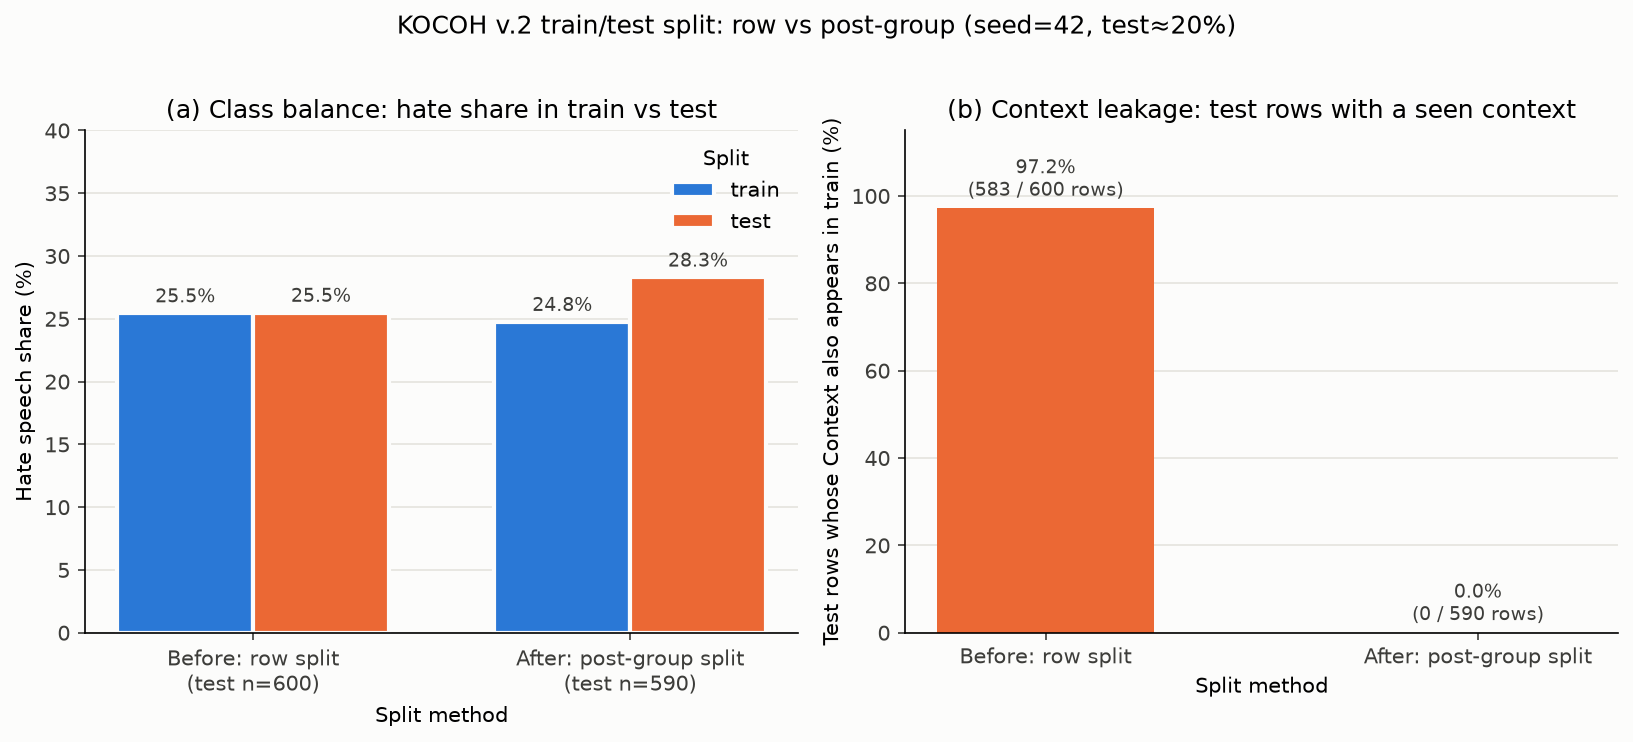

In [26]:
path = PROJECT_ROOT / "figures" / "kocoh_split_compare.png"
print(path.relative_to(PROJECT_ROOT))
display(Image(filename=str(path), width=900))

**읽는 법**
- (b) 이전 방식은 test 행 대부분의 지문이 train에 이미 있었고, 변경 방식은 0%입니다 → 겹침 문제가 해결됐습니다.
- (a) 대가로 test 혐오 비율이 train과 몇 %p 차이 납니다. 묶음째 나누면 비율을 완벽히 맞출 수 없기 때문입니다.
- test가 소수의 `post_group` 으로만 이뤄져 있어, 어떤 게시글이 test에 들어갔는지에 따라 점수가 흔들릴 수 있습니다.

## 요약 (실험 이름 / 설정 / 지표 / 결과 파일)

- **실험 이름**: kocoh_v2_eda_group_split
- **설정**: seed=42, data=data/KOCOH_v.2.csv, split=post_group 단위 StratifiedGroupKFold(5) 첫 fold, stratify=Hate speech, 누설 열 제외=Type·Date·Source·Link·Title, 표준화=context_len·comment_len (train fit)
- **지표**: 원본 3000행×18열, 메타 4열 결측비율=25.467%, 혐오 비율=25.467%; 변경 분할 train=2410 / test=590, train 혐오=24.772% / test 혐오=28.305%, train에서 본 Context인 test 행 이전 97.167% → 변경 0%, 지운 행=0
- **결과 파일**: `figures/kocoh_missing_ratio.png`, `figures/kocoh_class_ratio.png`, `figures/kocoh_split_compare.png` (생성 스크립트: `src/preprocess.py`)

---

## 📝 주의사항 메모

1. **`Type` 은 정답을 100% 결정한다.** `Type=1` 은 전부 혐오, `Type=2`·`3` 은 전부 비혐오다. 입력 특성으로 쓰면 모델이 댓글이 아니라 `Type` 만 보고 정답을 맞히므로 반드시 제외한다 (`load_and_split` 에서 제외됨).
2. **메타 열의 결측 여부도 라벨을 누설한다.** `Date`·`Source`·`Link`·`Title` 은 `Type=2` 의 764행에서만 동시에 비어 있고, 이 행은 모두 비혐오다. 결측 행을 지우면 비혐오 764행이 통째로 사라지고, 결측 여부를 특성으로 쓰면 정답이 샌다 → 행을 지우지 말고 열 자체를 제외한다.
3. **분할은 행 단위가 아니라 게시글 묶음(`post_group`) 단위로 한다.** 행 단위로 나누면 test 행의 약 97%가 train에서 이미 본 지문(Context)을 갖는다. 이러면 Context + Comment 모델 점수가 부풀려져 프로젝트의 핵심 비교가 왜곡된다.
4. **`Set` 만으로 묶어도 부족하다.** `Set` 은 같은 원글의 Context 변형 묶음이고, 18개 Context 문장은 여러 `Set` 에 동시에 나온다. 그래서 Context를 공유하는 Set을 이어 붙인 `post_group` 으로 나눈다.
5. **변경 분할의 한계.** test 크기는 정확히 20%가 아니고(약 19.7%), 혐오 비율도 train과 몇 %p 다르며, test가 소수의 게시글 묶음으로 이뤄진다. 하나의 test 점수에 과하게 의존하지 말고, 가능하면 5개 fold 전체로 교차검증해 평균·표준편차를 함께 보고한다.
6. **전처리는 train으로만 fit 한다.** 결측 대체값(중앙값)과 `StandardScaler` 는 train 통계만 쓰므로 test 표준화 평균이 0이 아닌 것이 정상이다. 게시글 단위로 나누면 test 지문 길이가 train과 달라 이 차이가 더 커질 수 있다.
7. **보조 라벨 열은 입력이 아니다.** `Counter speech`, `Gender`, `Disability`, `Race/Nationality`, `Region (Korea)`, `Age`, `Profanity`, `Ikiyano-style` 은 혐오 유형 등을 표시한 라벨이므로 입력으로 쓰면 누설이다. `post_group`·`Set`·`Index` 도 분할·식별용이지 입력 특성이 아니다.
8. **클래스 불균형** (비혐오 약 75% : 혐오 약 25%) 이 있으므로 정확도보다 macro-F1 등으로 평가한다.
9. **그림 파일.** `figures/kocoh_split_class_ratio.png` 는 **이전 행 단위 분할** 결과로 그린 그림이므로 현재 분할을 나타내지 않는다. 현재 분할은 `figures/kocoh_split_compare.png` 를 본다. `python src/preprocess.py --eda` 는 EDA 그림 2장을, 기본 실행은 `kocoh_split_compare.png` 를 덮어쓴다.